# 06: summary scoreboard

This notebook reads the numbers the other notebooks saved in `notebooks/results/<machine>/` (run 01 to 05 first) and puts them side by side. Every comparison is at the **largest size** each notebook raced, because that's where a speed library has to earn its keep.

The scoreboard and chart below show **this machine**. If other machines have results in the folder, the section after them compares machines.

"vs sklearn" above 1 means faster than scikit-learn's default. For PCA the baseline is `PCA()` with its default solver.

In [1]:
import sys
sys.path.insert(0, ".")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from bench_utils import load_results, ENGINE_COLORS, machine_info, machine_slug, machines_with_results

pd.set_option("display.float_format", "{:,.2f}".format)
%matplotlib inline

COLUMN_ORDER = ["sklearn", "sklearn (svd_solver=full)", "sklearn (svd_solver=randomized)",
                "numpy", "mlx", "rust", "rust-blas"]

def at_largest(df, size_col):
    return df[df[size_col] == df[size_col].max()]

def scoreboard(machine=None):
    parts = []
    knn, _ = load_results("knn", machine)
    parts.append(at_largest(knn, "train rows").assign(algorithm="KNN (predict)", measure="predict s"))
    km, _ = load_results("kmeans", machine)
    parts.append(at_largest(km, "rows").assign(algorithm="k-means (per iteration)", measure="s per iteration"))
    ridge, _ = load_results("ridge", machine)
    parts.append(at_largest(ridge, "rows").assign(algorithm="Ridge (fit)", measure="fit s"))
    pca, _ = load_results("pca", machine)
    pca = pca.rename(columns={"vs sklearn default": "vs sklearn"})
    pca["engine"] = pca["engine"].replace({"sklearn (svd_solver=auto)": "sklearn"})
    parts.append(at_largest(pca, "rows").assign(algorithm="PCA (fit)", measure="fit s"))
    tree, _ = load_results("tree", machine)
    parts.append(at_largest(tree, "depth").assign(algorithm="Decision tree (fit)", measure="fit s"))
    board = pd.concat(parts, ignore_index=True)
    board["seconds"] = [row[row["measure"]] for _, row in board.iterrows()]
    return board[["algorithm", "engine", "seconds", "vs sklearn"]]

board = scoreboard()
print("machine:", machine_slug())
board.pivot(index="algorithm", columns="engine", values="vs sklearn").reindex(
    columns=[c for c in COLUMN_ORDER if c in board["engine"].unique()])

machine: macos-arm64-apple-m4


engine,sklearn,sklearn (svd_solver=full),sklearn (svd_solver=randomized),numpy,mlx,rust,rust-blas
algorithm,,,,,,,
Decision tree (fit),1.00,NaN,NaN,0.34,NaN,2.29,NaN
KNN (predict),1.00,NaN,NaN,0.12,0.84,0.58,2.87
PCA (fit),1.00,0.02,0.07,0.56,0.58,NaN,NaN
Ridge (fit),1.00,NaN,NaN,1.21,1.13,NaN,NaN
k-means (per iteration),1.00,NaN,NaN,0.09,0.37,1.80,NaN


## Speed vs scikit-learn, by algorithm

Each bar is one of this project's engines. The gray line at 1× is scikit-learn; bars to the right are faster. The x axis is logarithmic, so 0.5× (twice as slow) and 2× (twice as fast) sit the same distance from the line.

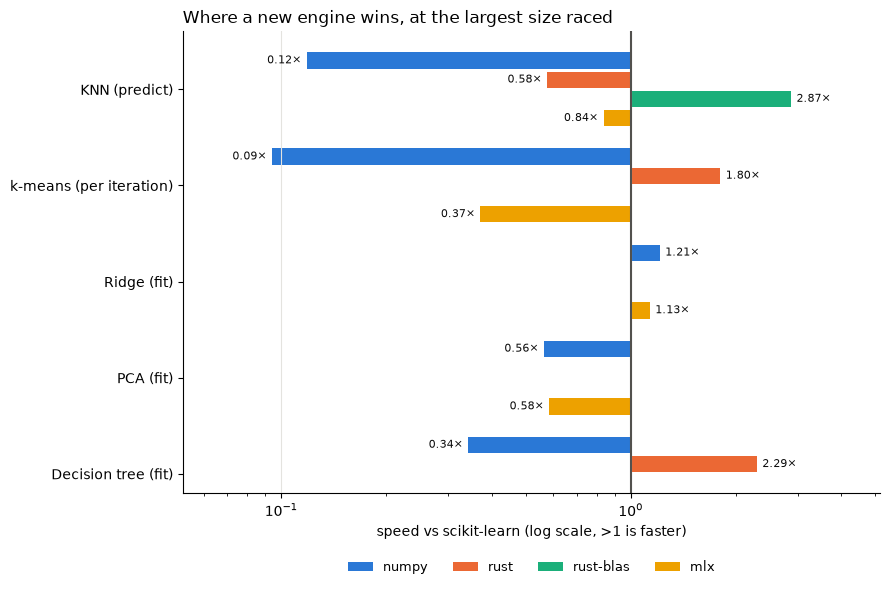

In [2]:
engines = [e for e in ENGINE_COLORS if e in board["engine"].unique()]
algos = list(dict.fromkeys(board["algorithm"]))
fig, ax = plt.subplots(figsize=(9, 6))
bar_h = 0.8 / len(engines)
for j, engine in enumerate(engines):
    for i, algo in enumerate(algos):
        row = board[(board["algorithm"] == algo) & (board["engine"] == engine)]
        if row.empty:
            continue
        v = float(row["vs sklearn"].iloc[0])
        y = i + (j - (len(engines) - 1) / 2) * bar_h
        lo, hi = min(v, 1.0), max(v, 1.0)  # each bar grows out from the 1x line
        ax.barh(y, hi - lo, height=bar_h - 0.03, left=lo, color=ENGINE_COLORS[engine],
                label=engine if engine not in ax.get_legend_handles_labels()[1] else None)
        ax.annotate(f"{v:.2f}×", (v, y), xytext=(4 if v >= 1 else -4, 0), textcoords="offset points",
                    ha="left" if v >= 1 else "right", va="center", fontsize=8, color="#0b0b0b")
ax.set_xscale("log")
ax.axvline(1, color="#52514e", linewidth=1.5)
ax.set_yticks(range(len(algos)), algos)
ax.invert_yaxis()
ax.set_xlabel("speed vs scikit-learn (log scale, >1 is faster)")
ax.set_title("Where a new engine wins, at the largest size raced", loc="left", fontsize=12)
ax.grid(True, axis="x", color="#e4e3df", linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)
handles, labels = ax.get_legend_handles_labels()
seen = dict(zip(labels, handles))
ax.legend(seen.values(), seen.keys(), frameon=False, fontsize=9, loc="upper center",
          bbox_to_anchor=(0.5, -0.12), ncol=len(seen))
vals = board.loc[board["engine"].isin(engines), "vs sklearn"]
ax.set_xlim(vals.min() / 1.8, vals.max() * 1.8)
from pathlib import Path
Path("../docs").mkdir(exist_ok=True)
fig.savefig(f"../docs/scoreboard-{machine_slug()}.png", dpi=150, bbox_inches="tight")
plt.show()

## Single-row latency (KNN)

The batch numbers above hide the case a robot or a live API cares about: one prediction at a time.

In [3]:
_, payload = load_results("knn")
pd.DataFrame(payload["notes"]["latency"])[["train rows", "engine", "median µs", "vs sklearn"]]

,train rows,engine,median µs,vs sklearn
0,10000,sklearn,422.90,1.00
1,10000,numpy,92.81,4.56
2,10000,rust,48.63,8.70
3,10000,rust-blas,36.98,11.44
4,10000,mlx,391.79,1.08
5,200000,sklearn,"2,322.98",1.00
6,200000,numpy,"1,189.73",1.95
7,200000,rust,749.08,3.10
8,200000,rust-blas,836.75,2.78
9,200000,mlx,965.62,2.41


## Across machines

The same races on every machine that has a results folder. Each cell is speed vs scikit-learn *on that machine*, so it answers "does the engine's advantage carry over?", not "which computer is faster".

In [4]:
machines = machines_with_results()
if len(machines) < 2:
    print(f"Only one machine has results so far ({', '.join(machines)}). "
          "Run ./run_all.sh on another machine and add its notebooks/results/<machine>/ folder.")
else:
    cross = pd.concat([scoreboard(m).assign(machine=m) for m in machines])
    cross = cross[~cross["engine"].str.startswith("sklearn")]
    display(cross.pivot_table(index=["algorithm", "engine"], columns="machine", values="vs sklearn").round(2))
    for m in machines:
        info = load_results("knn", m)[1]["machine"]
        print(f"{m}: {info['cpu']} | {info['os']} | numpy {info['numpy']} | rust-blas uses {info['rust-blas matrix library']}")

Only one machine has results so far (macos-arm64-apple-m4). Run ./run_all.sh on another machine and add its notebooks/results/<machine>/ folder.


## What the five races say

*The numbers quoted here come from the Apple M4 run committed with this repo. Re-running will shift them a little, but the pattern should hold.*

**1. Python on top of NumPy loses almost everywhere.** The NumPy engines were 6 to 12 times slower than scikit-learn on KNN and k-means, and up to 3 times slower on deep trees. Each time, the cause was a memory-bound step that scikit-learn runs in compiled code:
- picking the k smallest distances
- summing rows per cluster
- one Python call per tree node

The one NumPy win, Ridge, came from a better formulation, not a faster engine.

**2. The GPU (MLX) ties at best.** It ran 0.8 to 1.8× on KNN, 0.4 to 0.5× on k-means, and 0.6 to 1.3× on Ridge. Pure Python on the GPU still has to write large intermediate matrices to memory and read them back.

**3. Compiled Rust wins clearly in 3 of 5 algorithms:**

| Algorithm | Rust vs scikit-learn | What made it win |
|---|---|---|
| KNN, batch | **2.9 to 4.4× faster** (`rust-blas`) | Rust controls the loop; Accelerate's matrix units compute the distances |
| KNN, one row | **8.7 to 11.4× faster** on 10k rows, about 3× on 200k | no per-call Python overhead |
| k-means | **1.8 to 2.1× faster** (a tie at k = 256) | assigning and summing happen in one pass, on every core |
| Decision tree, fit | **2.3 to 3.6× faster** on the full data | histogram algorithm plus parallel counting (and slightly higher accuracy) |
| Decision tree, predict | **7.4 to 7.9× faster** | compares raw values, with no binning, on every core |

**4. Two algorithms had no headroom.** Ridge and PCA are one big matrix multiply, which scikit-learn already hands to the same hardware.
- **Ridge:** our version is only 1.05 to 1.2× faster. On 4 million rows, though, it lands about 380 times closer to the exact answer, because it centers the data in chunks and sums in 64-bit.
- **PCA:** scikit-learn's default was **1.7 to 2.1× faster than ours**.

**5. The biggest speed difference wasn't the engine.** In PCA, the same library on the same data took 0.13 seconds or 5.6 seconds, depending on one setting (`svd_solver="auto"` vs `"full"`). That is a **42× gap**. The best engine win anywhere in these races was under 5× on batch work. Choosing the right algorithm and settings mattered more than making any one algorithm faster.

**6. Speed came with correctness work.** Getting each engine to win *and* match scikit-learn took real debugging. Each of these bugs is now covered by a test:
- k-means results that changed from run to run
- a Ridge shortcut that quietly lost precision
- tree prediction spending 98% of its time binning its input

That work multiplies with every algorithm you add.

## What this means for anyone building a faster ML library

**Path A: an alternative to scikit-learn.** It's possible one algorithm at a time. Expect roughly 2 to 4× on batch work and up to 10× on single predictions, but only with compiled code, only on some algorithms, and only after careful engineering and testing for each one. scikit-learn has hundreds of estimators.

**Path B: a navigator for scikit-learn.** The single biggest measured gap (42×) came from choosing the right solver, which is exactly what a navigator does. It works for every scikit-learn algorithm on day one.

**What happened next.** This project began as the first version of [autoalgo](https://github.com/herodthegreater/autoalgo). These results moved autoalgo to path B: it's being rebuilt as a tool that helps people choose and understand scikit-learn algorithms. The speed research continues here.

## Open question: is it Rust, or is it Apple?

Three of the Rust wins lean on Apple Accelerate, which can use the M4's matrix units. The next run is on an Intel machine running Linux, where scikit-learn uses OpenBLAS and the Rust engines use a pure-Rust matrix multiply. [`PREDICTIONS.md`](../PREDICTIONS.md) records what that run should show, written and committed before it happened. When its results folder lands, the "Across machines" table above fills in.

In [5]:
pd.Series(machine_info(), name="machine these numbers came from")

machine                                    macos-arm64-apple-m4
cpu                                                    Apple M4
cores                              4 performance + 6 efficiency
ram_gb                                                       24
os                          macOS-26.6.1-arm64-arm-64bit-Mach-O
python                                                   3.13.5
numpy                                  2.5.4 (BLAS: accelerate)
sklearn                                                   1.9.1
rust-blas matrix library                       Apple Accelerate
mlx                                     0.32.4 (Device(gpu, 0))
Name: machine these numbers came from, dtype: object